# E06 · Flat optics and wrapped phase

A thin element controls phase through height. Wrapping that phase makes a shallow optic, while quantization and colour reveal the price of the simplification.

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Convert physical height into a phase delay.
- Explain why phase wrapping is equivalent at one design wavelength.
- Quantify staircase efficiency and identify when the thin-element model fails.

**Model:** 1D scalar thin-element lens, fixed n = 1.5, design λ₀ = 550 nm, aperture radius 15 μm and paraxial focal length 120 μm. Propagation uses exact scalar ASM. Fresnel reflection, material dispersion, polarization, and sidewall coupling are omitted.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e06_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.12.13 | NumPy 2.4.3 | SciPy 1.16.3 | Matplotlib 3.11.2


## 1 · A height profile becomes an optical phase

For a nondispersive thin dielectric of index n in air, $\phi=2\pi(n-1)h/\lambda$.
A paraxial converging lens has phase $-\pi x^2/(\lambda_0 f_0)$, plus an irrelevant constant.
Subtracting integer multiples of $h_{2\pi}=\lambda_0/(n-1)$ preserves the field
at the design wavelength. The fabricated height stays fixed when wavelength changes.
**Predict:** will the unwrapped and wrapped profiles still be equivalent at 650 nm?

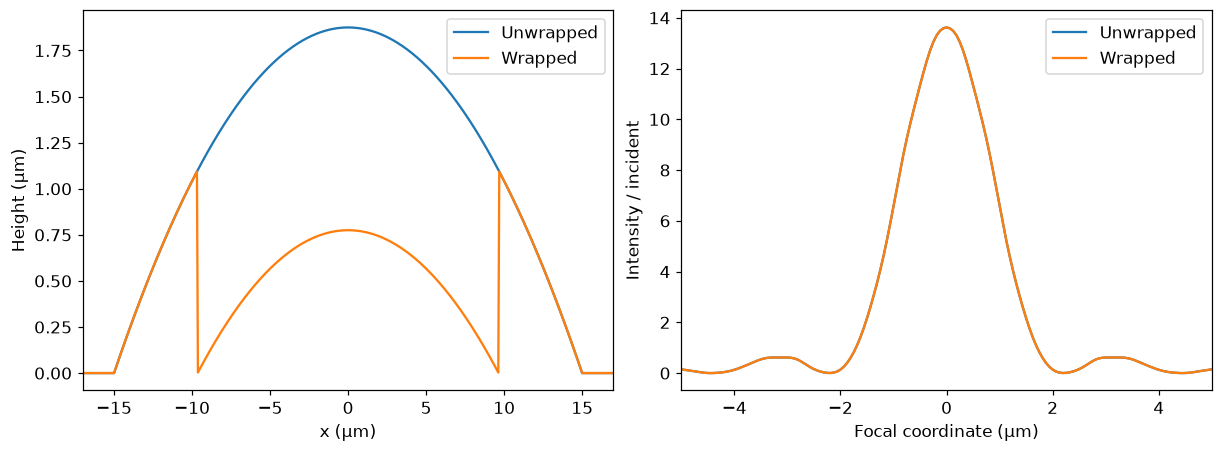

In [2]:
N=2048;dx=.0625;x=(np.arange(N)-N//2)*dx
lambda0=.55;n_glass=1.5;f0=120.;R=15.
pupil=(abs(x)<=R).astype(float)
height=np.where(pupil>0,(R*R-x*x)/(2*f0*(n_glass-1)),0)
h2pi=lambda0/(n_glass-1)
wrapped=np.mod(height,h2pi)
def field(h,lam):return pupil*np.exp(2j*np.pi*(n_glass-1)*h/lam)
def propagate(u,lam,z):
    fx=np.fft.fftfreq(N,dx)
    kz=2*np.pi*np.sqrt((1/lam**2-fx*fx).astype(complex))
    return np.fft.ifft(np.fft.fft(u)*np.exp(1j*z*kz))
assert np.max(abs(field(height,lambda0)-field(wrapped,lambda0)))<1e-12
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(x,height,label="Unwrapped");ax[0].plot(x,wrapped,label="Wrapped")
ax[0].set(xlim=(-17,17),xlabel="x (μm)",ylabel="Height (μm)");ax[0].legend()
for h,label in [(height,"Unwrapped"),(wrapped,"Wrapped")]:
    ax[1].plot(x,abs(propagate(field(h,lambda0),lambda0,f0))**2,label=label)
ax[1].set(xlim=(-5,5),xlabel="Focal coordinate (μm)",ylabel="Intensity / incident");ax[1].legend()
show(fig,"01-wrapping-equivalence")

## 2 · Quantization sends power to other orders

A uniform M-level approximation to one 2π blazed-grating period has ideal first-order
efficiency $\mathrm{sinc}^2(1/M)$, using sinc(x)=sin(πx)/(πx). This is an order-efficiency
benchmark, not the total efficiency of every finite lens or metasurface.

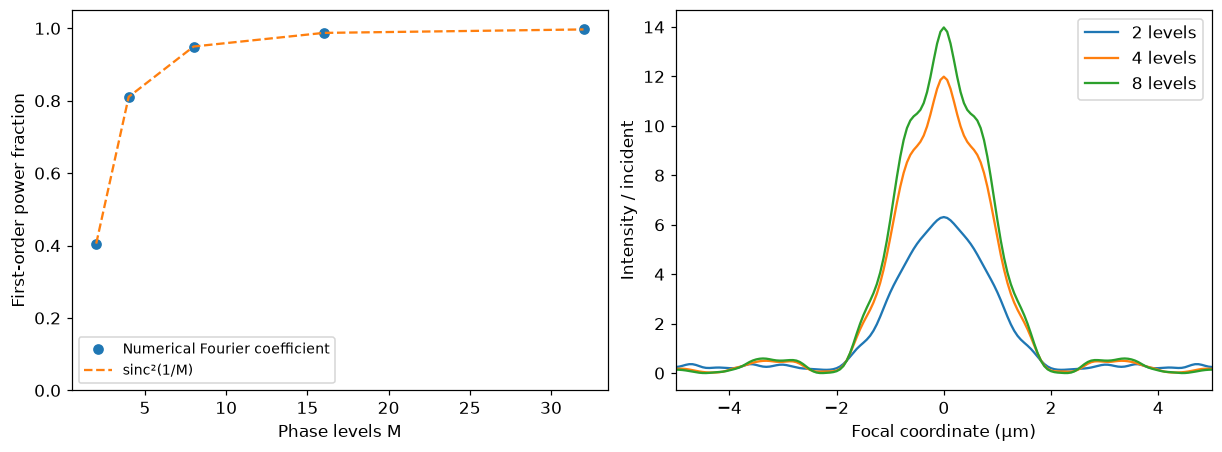

Max grating-efficiency quadrature error: 7.635241328074471e-10


In [3]:
t=(np.arange(65536)+.5)/65536
levels=np.array([2,4,8,16,32])
efficiencies=[]
for M in levels:
    transmission=np.exp(2j*np.pi*np.floor(t*M)/M)
    amplitude_order=np.mean(transmission*np.exp(-2j*np.pi*t))
    efficiencies.append(abs(amplitude_order)**2)
exact=np.sinc(1/levels)**2
assert np.max(abs(np.array(efficiencies)-exact))<1e-8
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(levels,efficiencies,"o",label="Numerical Fourier coefficient")
ax[0].plot(levels,exact,"--",label="sinc²(1/M)");ax[0].legend(fontsize=9)
ax[0].set(xlabel="Phase levels M",ylabel="First-order power fraction",ylim=(0,1.05))
for M in [2,4,8]:
    staircase=np.floor(wrapped/h2pi*M)*h2pi/M
    ax[1].plot(x,abs(propagate(field(staircase,lambda0),lambda0,f0))**2,label=f"{M} levels")
ax[1].set(xlim=(-5,5),xlabel="Focal coordinate (μm)",ylabel="Intensity / incident");ax[1].legend()
show(fig,"02-quantization")
print("Max grating-efficiency quadrature error:",np.max(abs(np.array(efficiencies)-exact)))

## 3 · Compare colours at fixed fabrication

The wrapped profile is a diffractive lens. Its first design-order focal length approximately
follows $f=f_0\lambda_0/\lambda$. The nondispersive unwrapped thin refractive lens stays near
f₀. Finite aperture, scalar nonparaxial phase, and interference between orders shift the
measured axial maximum slightly; inspect the curve rather than claiming exact equality.

Diffractive first-order prediction at 0.45 μm: 146.67 μm
Diffractive first-order prediction at 0.55 μm: 120.00 μm
Diffractive first-order prediction at 0.65 μm: 101.54 μm


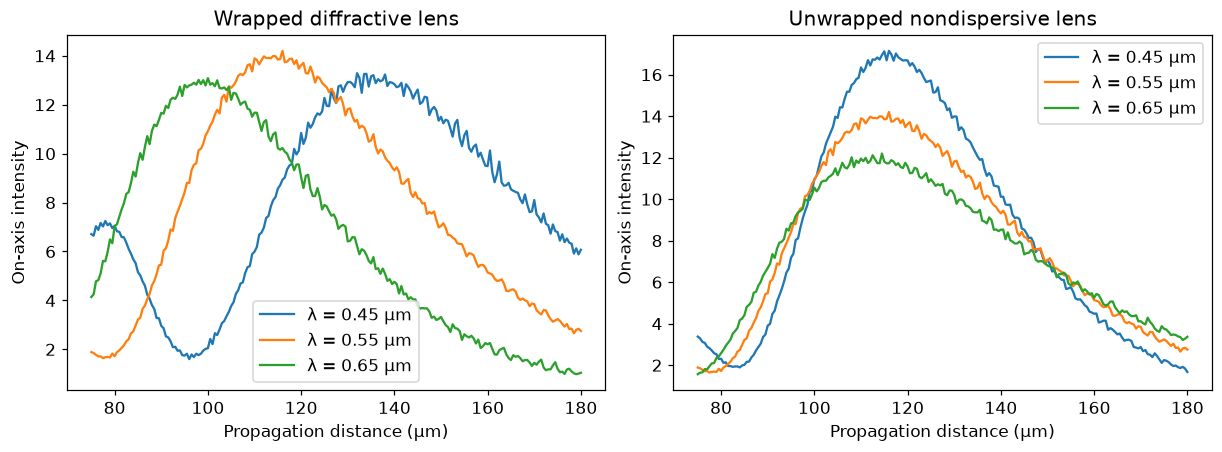

In [4]:
zs=np.linspace(75,180,211)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for lam in [.45,.55,.65]:
    for h,a in [(wrapped,ax[0]),(height,ax[1])]:
        u=field(h,lam)
        axial=np.array([abs(propagate(u,lam,z)[N//2])**2 for z in zs])
        a.plot(zs,axial,label=f"λ = {lam:.2f} μm")
    predicted=f0*lambda0/lam
    print(f"Diffractive first-order prediction at {lam:.2f} μm: {predicted:.2f} μm")
for a,title in zip(ax,["Wrapped diffractive lens","Unwrapped nondispersive lens"]):
    a.set(title=title,xlabel="Propagation distance (μm)",ylabel="On-axis intensity");a.legend()
show(fig,"03-chromatic-focus")

## Optional extension · Blur the height, then recompute the phase

Fabrication smoothing acts on the physical height; smoothing a wrapped phase phasor is
a different operation. This is only a manufacturing toy model: no vector scattering,
resonant nanostructures, Fresnel reflections, or index dispersion are included.

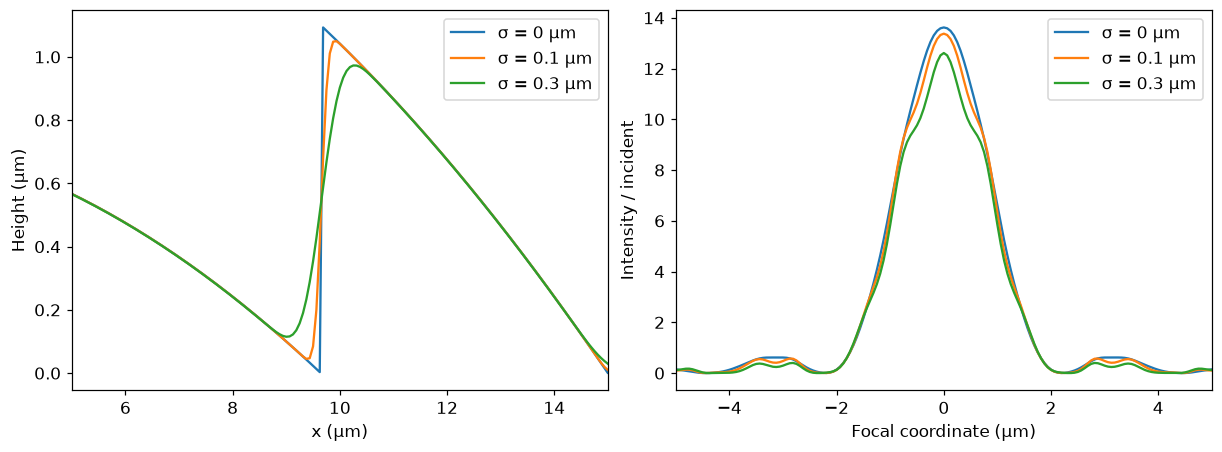

In [5]:
from scipy.ndimage import gaussian_filter1d
fig,ax=plt.subplots(1,2,figsize=(11,4))
for sigma_um in [0,.1,.3]:
    blurred=wrapped if sigma_um==0 else gaussian_filter1d(wrapped,sigma_um/dx)
    ax[0].plot(x,blurred,label=f"σ = {sigma_um} μm")
    ax[1].plot(x,abs(propagate(field(blurred,lambda0),lambda0,f0))**2,label=f"σ = {sigma_um} μm")
ax[0].set(xlim=(5,15),xlabel="x (μm)",ylabel="Height (μm)")
ax[1].set(xlim=(-5,5),xlabel="Focal coordinate (μm)",ylabel="Intensity / incident")
for a in ax:a.legend()
show(fig,"04-height-blur")

## A short lab report

**1. Verify wrapping.** Compare complex transmissions of continuous and wrapped profiles at two wavelengths.

**2. Measure order efficiency.** Compute the +1 Fourier coefficient of 2-, 4-, 8-, and 16-level phase ramps.

**3. Separate error sources.** Compare quantization, height smoothing, and pixel refinement.

### Worked reasoning

**Verify wrapping.** They agree at λ₀ up to floating-point error. At another wavelength the removed height need not be a full phase turn.

**Measure order efficiency.** Use a common unit-amplitude input and compare squared coefficient magnitude with sinc²(1/N).

**Separate error sources.** Quantization and smoothing alter the modeled device; pixel refinement changes its numerical representation. Full-wave model error is a separate issue.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [Levy, Mendlovic & Marom · Efficiency analysis of diffractive lenses](https://opg.optica.org/josaa/abstract.cfm?uri=josaa-18-1-86)
- [TU Delft · Wavefield propagation](https://qiweb.tudelft.nl/aoi/wavefieldpropagation/wavefieldpropagation/)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e06_figures.zip


/tmp/optics-notebooks-xppq4daw/E06/e06_figures.zip